# Análisis comparativo sobre la submuestra de 100 correos: Rspamd vs. LLM+MCP (veredicto) vs. LLM+MCP (explicación)

Compara tres sistemas sobre los mismos 100 correos de `eval_external_100.csv` (50 phishing de Phishing Pot +
50 legítimos de TREC 2007, submuestra estratificada de `eval_external.csv`):

- **Rspamd**: filtro basado en reglas (resultados tomados de la corrida sobre los 1,000 correos).
- **LLM+MCP, modo veredicto**: orquestador con los servidores archetype + virustotal (corrida sobre los 1,000).
- **LLM+MCP, modo explicación**: orquestador con los cuatro servidores MCP (corrida solo sobre estos 100).

## 1. Imports y carga de datos

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

RANDOM_STATE = 42
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 150, "savefig.bbox": "tight"})

# Carpeta experiments/ (funciona si el notebook se ejecuta desde experiments/ o desde la raíz del repo)
BASE = Path.cwd() if (Path.cwd() / "eval_system").exists() else Path.cwd() / "experiments"

RUTA_CSV = BASE / "external_eval" / "eval_external_100.csv"
RUTA_RSPAMD = BASE / "eval_system" / "rspamd_results_raw.jsonl"
RUTA_EXPLICACION = BASE / "eval_system" / "results_explicacion_100.jsonl"
# results_raw.jsonl (modo veredicto) puede estar en experiments/data/ o en data/ (raíz del repo)
RUTAS_VEREDICTO = [BASE / "data" / "results_raw.jsonl", BASE.parent / "data" / "results_raw.jsonl"]
RUTA_VEREDICTO = next((p for p in RUTAS_VEREDICTO if p.exists()), RUTAS_VEREDICTO[0])

FIGURES_DIR = BASE / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RSPAMD_SCORE_TOPE = 20.0  # divisor para normalizar el score crudo de Rspamd a [0, 1]

# Nombre, color y columnas de cada sistema (se reutiliza en todas las secciones)
SISTEMAS = {
    "rspamd": {"nombre": "Rspamd", "color": "tab:orange"},
    "veredicto": {"nombre": "LLM+MCP (veredicto)", "color": "tab:blue"},
    "explicacion": {"nombre": "LLM+MCP (explicación)", "color": "tab:green"},
}


def cargar_jsonl(ruta: Path) -> pd.DataFrame:
    with ruta.open(encoding="utf-8") as f:
        return pd.DataFrame([json.loads(linea) for linea in f if linea.strip()])

In [2]:
# Los 100 correos de referencia: id es la llave, label la etiqueta real
correos = pd.read_csv(RUTA_CSV, usecols=["id", "label", "source"])
ids_100 = set(correos["id"])

# Rspamd y veredicto se corrieron sobre los 1,000 correos: se filtran por los ids de la submuestra
rspamd = cargar_jsonl(RUTA_RSPAMD)
veredicto = cargar_jsonl(RUTA_VEREDICTO)
explicacion = cargar_jsonl(RUTA_EXPLICACION)

# Advertencia (sin fallar) si algún correo de la submuestra no aparece en un archivo de resultados
for nombre, tabla in [("rspamd_results_raw.jsonl", rspamd), ("results_raw.jsonl", veredicto),
                      ("results_explicacion_100.jsonl", explicacion)]:
    faltantes = sorted(ids_100 - set(tabla["id"]))
    con_error = int(tabla.loc[tabla["id"].isin(ids_100), "error"].notna().sum())
    if faltantes:
        print(f"ADVERTENCIA: {len(faltantes)} ids de la submuestra no están en {nombre}: {faltantes[:5]}"
              f"{' ...' if len(faltantes) > 5 else ''}")
    if con_error:
        print(f"ADVERTENCIA: {con_error} correos de la submuestra tienen error en {nombre}")
    print(f"{nombre}: {int(tabla['id'].isin(ids_100).sum())} de {len(ids_100)} correos de la submuestra")

# Scores normalizados a [0, 1]. Rspamd: score crudo / 20, recortado (hay scores por encima de 20).
# Los dos modos del LLM ya entregan puntaje_riesgo en [0, 1].
rspamd["rspamd_score"] = (rspamd["rspamd_score"] / RSPAMD_SCORE_TOPE).clip(0, 1)
veredicto = veredicto.rename(columns={"puntaje_riesgo": "veredicto_score", "clasificacion": "veredicto_clasificacion"})
explicacion = explicacion.rename(columns={"puntaje_riesgo": "explicacion_score", "clasificacion": "explicacion_clasificacion"})

# Un único DataFrame, una fila por correo
df = (correos
      .merge(rspamd[["id", "rspamd_score"]], on="id", how="left", validate="one_to_one")
      .merge(veredicto[["id", "veredicto_score", "veredicto_clasificacion"]], on="id", how="left", validate="one_to_one")
      .merge(explicacion[["id", "explicacion_score", "explicacion_clasificacion", "senales_count", "explicacion"]],
             on="id", how="left", validate="one_to_one"))

print(f"\nDataFrame combinado: {len(df)} correos | phishing: {int((df['label'] == 1).sum())} | legítimos: {int((df['label'] == 0).sum())}")

rspamd_results_raw.jsonl: 100 de 100 correos de la submuestra
results_raw.jsonl: 100 de 100 correos de la submuestra
results_explicacion_100.jsonl: 100 de 100 correos de la submuestra

DataFrame combinado: 100 correos | phishing: 50 | legítimos: 50


## 2. Umbrales de clasificación

- **Rspamd:** score normalizado ≥ 0.3 → phishing (equivale al umbral de 6.0 sobre 20 de la acción `add header`).
- **Veredicto:** score ≥ 0.5 → phishing.
- **Explicación:** score ≥ 0.5 → phishing.

In [3]:
UMBRALES = {"rspamd": 0.3, "veredicto": 0.5, "explicacion": 0.5}

for sistema, umbral in UMBRALES.items():
    score = df[f"{sistema}_score"]
    # Int64 (con nulos) para no romper si a algún correo le falta el score de un sistema
    df[f"{sistema}_pred"] = (score >= umbral).astype("Int64").where(score.notna())

# Comprobación: el umbral sobre el score debe coincidir con la clasificación que emitió el propio modelo
for sistema in ["veredicto", "explicacion"]:
    emitida = df[f"{sistema}_clasificacion"].map({"phishing": 1, "legitimo": 0})
    distintos = int((emitida != df[f"{sistema}_pred"]).sum())
    print(f"{SISTEMAS[sistema]['nombre']}: {distintos} correos donde el umbral {UMBRALES[sistema]} no coincide con el campo clasificacion")

COLUMNAS = ["id", "label", "rspamd_score", "rspamd_pred", "veredicto_score", "veredicto_pred",
            "explicacion_score", "explicacion_pred"]
df[COLUMNAS].head(10)

LLM+MCP (veredicto): 0 correos donde el umbral 0.5 no coincide con el campo clasificacion
LLM+MCP (explicación): 0 correos donde el umbral 0.5 no coincide con el campo clasificacion


,id,label,rspamd_score,rspamd_pred,veredicto_score,veredicto_pred,explicacion_score,explicacion_pred
0,trec_2007_21,0,0.2000,0,0.05,0,0.05,0
1,trec_2007_240,0,0.4050,1,0.08,0,0.08,0
2,trec_2007_136,0,0.5000,1,0.08,0,0.05,0
3,trec_2007_438,0,0.2500,0,0.85,1,0.72,1
4,trec_2007_84,0,0.3000,1,0.05,0,0.02,0
5,trec_2007_78,0,0.2050,0,0.05,0,0.02,0
6,phishing_pot_sample-1019,1,0.5675,1,0.65,1,0.85,1
7,trec_2007_42,0,0.3000,1,0.02,0,0.05,0
8,phishing_pot_sample-1062,1,0.4100,1,0.92,1,0.95,1
9,trec_2007_478,0,0.2500,0,0.08,0,0.05,0


## 3. Métricas por sistema

Cada sistema se evalúa sobre los correos para los que tiene score. Con solo 100 correos las métricas tienen
bastante incertidumbre, así que se añade un intervalo de confianza del 95 % por bootstrap.

In [4]:
def datos_sistema(sistema: str):
    """Etiquetas, predicciones y scores de un sistema, sin los correos que no tengan resultado."""
    validos = df[df[f"{sistema}_score"].notna()]
    return (validos["label"].to_numpy(), validos[f"{sistema}_pred"].astype(int).to_numpy(),
            validos[f"{sistema}_score"].to_numpy())


filas = {}
for sistema, info in SISTEMAS.items():
    y, pred, score = datos_sistema(sistema)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    filas[info["nombre"]] = {
        "Correos": len(y),
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y, score),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }

tabla_metricas = pd.DataFrame(filas).T
tabla_metricas[["Correos", "TP", "FP", "FN", "TN"]] = tabla_metricas[["Correos", "TP", "FP", "FN", "TN"]].astype(int)
METRICAS = ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]
tabla_metricas.style.format("{:.4f}", subset=METRICAS).highlight_max(subset=METRICAS, color="#b7e4c7", props="color: black; font-weight: bold; background-color: #b7e4c7")

,Correos,Accuracy,Precision,Recall,F1,AUC-ROC,TP,FP,FN,TN
Rspamd,100,0.7400,0.7000,0.8400,0.7636,0.8194,42,18,8,32
LLM+MCP (veredicto),100,0.8900,0.9333,0.8400,0.8842,0.9692,42,3,8,47
LLM+MCP (explicación),100,0.9100,0.9556,0.8600,0.9053,0.9804,43,2,7,48


In [5]:
# Intervalos de confianza del 95 % por bootstrap (2,000 remuestreos con reemplazo de los correos)
N_BOOTSTRAP = 2000
rng = np.random.default_rng(RANDOM_STATE)

ic = {}
for sistema, info in SISTEMAS.items():
    y, pred, score = datos_sistema(sistema)
    muestras = {"Accuracy": [], "F1": [], "AUC-ROC": []}
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:  # el AUC necesita ambas clases
            continue
        muestras["Accuracy"].append(accuracy_score(y[idx], pred[idx]))
        muestras["F1"].append(f1_score(y[idx], pred[idx], zero_division=0))
        muestras["AUC-ROC"].append(roc_auc_score(y[idx], score[idx]))
    ic[info["nombre"]] = {m: f"{np.percentile(v, 2.5):.3f} – {np.percentile(v, 97.5):.3f}" for m, v in muestras.items()}

pd.DataFrame(ic).T.rename(columns=lambda c: f"{c} (IC 95 %)")

,Accuracy (IC 95 %),F1 (IC 95 %),AUC-ROC (IC 95 %)
Rspamd,0.650 – 0.820,0.673 – 0.845,0.731 – 0.902
LLM+MCP (veredicto),0.830 – 0.950,0.806 – 0.947,0.935 – 0.996
LLM+MCP (explicación),0.850 – 0.960,0.837 – 0.962,0.956 – 0.997


## 4. Matrices de confusión

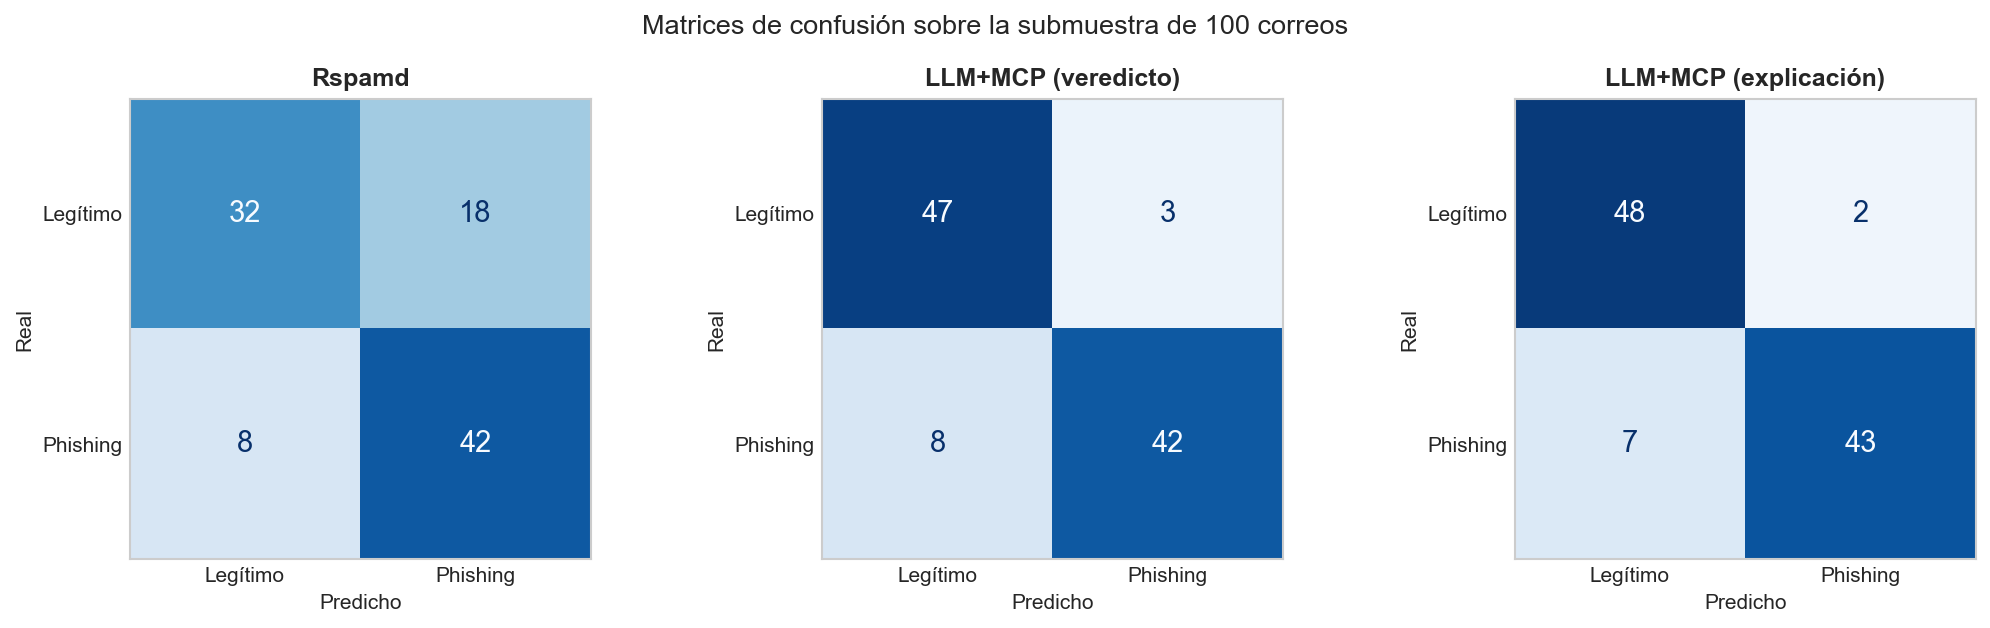

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

for ax, (sistema, info) in zip(axes, SISTEMAS.items()):
    y, pred, _ = datos_sistema(sistema)
    ConfusionMatrixDisplay.from_predictions(
        y, pred, labels=[0, 1], display_labels=["Legítimo", "Phishing"],
        cmap="Blues", colorbar=False, ax=ax, text_kw={"fontsize": 14},
        im_kw={"vmin": 0, "vmax": 50},
    )
    ax.set_title(info["nombre"], fontweight="bold")
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
    ax.grid(False)

fig.suptitle("Matrices de confusión sobre la submuestra de 100 correos", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "confusion_matrices_100.png")
plt.show()

## 5. Curvas ROC

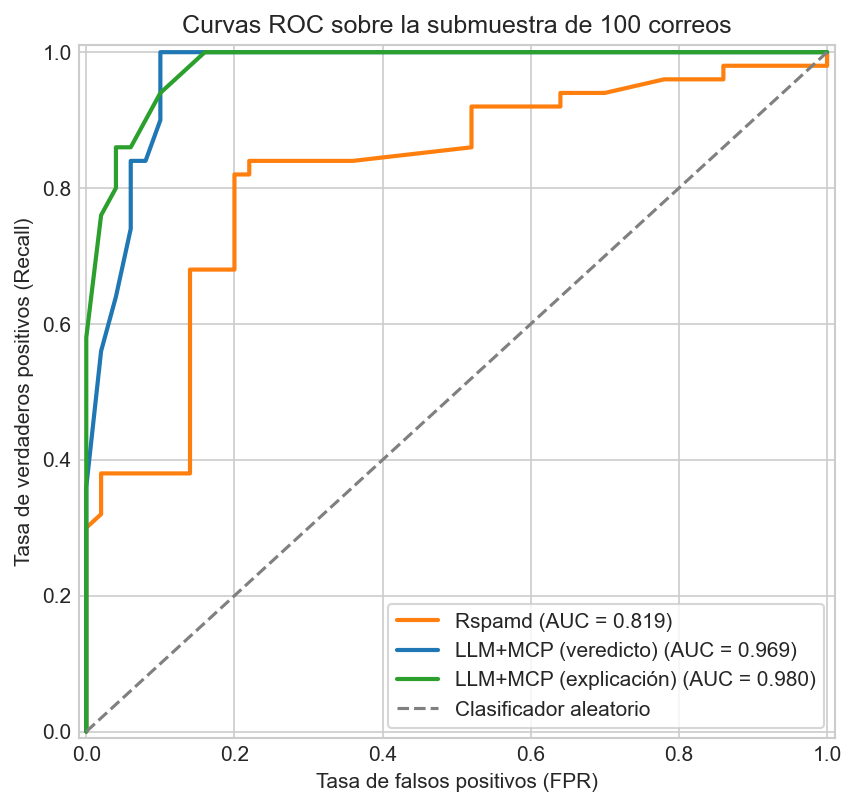

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 6))

for sistema, info in SISTEMAS.items():
    y, _, score = datos_sistema(sistema)
    fpr, tpr, _ = roc_curve(y, score)
    ax.plot(fpr, tpr, color=info["color"], linewidth=2, label=f"{info['nombre']} (AUC = {roc_auc_score(y, score):.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Clasificador aleatorio")
ax.set_xlabel("Tasa de falsos positivos (FPR)")
ax.set_ylabel("Tasa de verdaderos positivos (Recall)")
ax.set_title("Curvas ROC sobre la submuestra de 100 correos")
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)
ax.legend(loc="lower right", frameon=True)
fig.savefig(FIGURES_DIR / "roc_curves_100.png")
plt.show()

## 6. Análisis de errores: ¿dónde difieren veredicto y explicación?

Correos en los que los dos modos del orquestador dan una clasificación distinta. `acierta` indica cuál de
los dos coincide con la etiqueta real.

In [8]:
ambos = df[df["veredicto_pred"].notna() & df["explicacion_pred"].notna()]
difieren = ambos[ambos["veredicto_pred"] != ambos["explicacion_pred"]].copy()
difieren["acierta"] = np.where(difieren["veredicto_pred"] == difieren["label"], "veredicto", "explicación")

print(f"Correos donde veredicto y explicación difieren: {len(difieren)} de {len(ambos)}")
print(difieren["acierta"].value_counts().rename("correos en que acierta cada modo").to_string())

difieren[["id", "label", "veredicto_score", "explicacion_score", "veredicto_pred", "explicacion_pred", "acierta"]].reset_index(drop=True)

Correos donde veredicto y explicación difieren: 4 de 100
acierta
explicación    3
veredicto      1


,id,label,veredicto_score,explicacion_score,veredicto_pred,explicacion_pred,acierta
0,phishing_pot_sample-1252,1,0.15,0.65,0,1,explicación
1,trec_2007_384,0,0.72,0.25,1,0,explicación
2,phishing_pot_sample-1254,1,0.65,0.15,1,0,veredicto
3,phishing_pot_sample-1376,1,0.15,0.68,0,1,explicación


In [9]:
# Acuerdo entre los dos modos del LLM y errores que comparten
acierta_v = ambos["veredicto_pred"] == ambos["label"]
acierta_e = ambos["explicacion_pred"] == ambos["label"]
acuerdo = pd.Series({
    "Ambos modos correctos": int((acierta_v & acierta_e).sum()),
    "Solo veredicto correcto": int((acierta_v & ~acierta_e).sum()),
    "Solo explicación correcto": int((~acierta_v & acierta_e).sum()),
    "Ambos modos incorrectos": int((~acierta_v & ~acierta_e).sum()),
}, name="Correos").to_frame()
display(acuerdo)

# Errores compartidos por los dos modos: no dependen de los servidores MCP adicionales
compartidos = ambos[~acierta_v & ~acierta_e]
compartidos[["id", "label", "rspamd_score", "rspamd_pred", "veredicto_score", "explicacion_score"]].reset_index(drop=True)

,Correos
Ambos modos correctos,88
Solo veredicto correcto,1
Solo explicación correcto,3
Ambos modos incorrectos,8


,id,label,rspamd_score,rspamd_pred,veredicto_score,explicacion_score
0,trec_2007_438,0,0.250000,0,0.85,0.72
1,trec_2007_329,0,0.200000,0,0.78,0.85
2,phishing_pot_sample-1309,1,0.490000,1,0.15,0.25
3,phishing_pot_sample-1080,1,0.527500,1,0.15,0.25
4,phishing_pot_sample-1364,1,0.360500,1,0.25,0.25
5,phishing_pot_sample-1353,1,0.669500,1,0.15,0.15
6,phishing_pot_sample-1368,1,0.450000,1,0.25,0.15
7,phishing_pot_sample-1427,1,0.445415,1,0.25,0.25


## 7. Resumen para el capítulo de resultados

> Cifras de la corrida del 2026-10-04. Si se regenera algún archivo de resultados, actualizar esta tabla con la de la sección 3.

**Tabla. Desempeño de los tres sistemas sobre la submuestra de 100 correos (50 phishing, 50 legítimos).**

| Sistema | Accuracy | Precision | Recall | F1 | AUC-ROC | TP | FP | FN | TN |
|---|---|---|---|---|---|---|---|---|---|
| Rspamd (umbral 6.0) | 0.740 | 0.700 | 0.840 | 0.764 | 0.819 | 42 | 18 | 8 | 32 |
| LLM+MCP, modo veredicto | 0.890 | 0.933 | 0.840 | 0.884 | 0.969 | 42 | 3 | 8 | 47 |
| LLM+MCP, modo explicación | **0.910** | **0.956** | **0.860** | **0.905** | **0.980** | 43 | 2 | 7 | 48 |

**Lectura.**

- Los dos modos del sistema LLM+MCP superan a Rspamd en todas las métricas salvo en Recall, donde el modo
  veredicto empata con Rspamd (0.840) y el modo explicación queda un correo por encima (0.860). La ventaja
  está en las falsas alarmas: Rspamd marca 18 de los 50 legítimos, frente a 3 y 2 de los modos del LLM.
- El modo explicación, que usa los cuatro servidores MCP, obtiene los mejores valores, pero la diferencia
  con el modo veredicto es de **2 correos sobre 100** (un falso positivo y un falso negativo menos). Los
  intervalos de confianza de la sección 3 se solapan casi por completo, así que con esta muestra **no se
  puede afirmar que el modo explicación clasifique mejor**; sí se puede afirmar que añadir los servidores de
  conocimiento y coherencia no degrada la clasificación.
- Los dos modos discrepan solo en 4 correos: el modo explicación acierta en 3 (dos phishing que el veredicto
  dejaba pasar y un legítimo que marcaba) y el veredicto en 1. Los otros 8 errores son compartidos por ambos
  modos (6 phishing no detectados y 2 legítimos marcados), lo que indica que no dependen de qué servidores
  MCP se consulten.
- Estos resultados sobre 100 correos son consistentes con los de los 1,000 (veredicto: F1 0.911, AUC 0.975;
  Rspamd: F1 0.804, AUC 0.839), aunque algo más bajos para ambos sistemas en esta submuestra.

**Limitaciones a declarar.** (1) La muestra es de 100 correos; una diferencia de uno o dos correos mueve las
métricas en 1–2 puntos. (2) El sistema LLM recibió solo el cuerpo del correo (`body`), mientras que Rspamd
recibió el correo con encabezados (`raw_text`). (3) Los legítimos de TREC tienen encabezados reconstruidos, lo
que probablemente infla los falsos positivos de Rspamd. (4) El modo explicación tardó una mediana de 64 s por
correo, frente a 24 s del modo veredicto en estos mismos correos; su costo en tokens no quedó registrado.